# Exploratory Data Analysis: Superstore Retail Sales

**Datheon Data Analytics & Power BI Internship, Task 1**

**Goal:** clean the Superstore dataset, profile missing values, and uncover what drives sales and profit.

**Business questions**
1. How have sales and profit grown, and how seasonal is demand?
2. Which categories, regions and customer segments earn the money, and which quietly lose it?
3. How are purchases spread across customers?
4. How sensitive is profit to discounting?

**Contents:** 1. Load and inspect, 2. Missing-value profiling, 3. Cleaning, 4. Overview, 5. Customers, 6. Seasonality, 7. Category / Region / Segment, 8. Discount sensitivity, 9. Returns, 10. Executive takeaways

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
Path("images").mkdir(exist_ok=True)

money_k = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")
pct0 = mtick.PercentFormatter(1.0, decimals=0)
DATA_PATH = "data/superstore_sales.csv"

## 1. Load and inspect

I read every column as text first (`dtype=str`) so nothing is silently converted, then check the shape and null counts before deciding how to clean.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
print("Shape:", raw.shape)
raw.isna().sum()

Shape: (10800, 21)


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

## 2. Missing-value profiling

Every column shows exactly **806** nulls, which is suspicious. Real missing data is rarely this uniform, so I look at the rows where it happens.

In [3]:
null_rows = raw[raw["Order Date"].isna()]
print("Rows with a null Order Date:", len(null_rows))
null_rows.iloc[:, :3].head(12)

Rows with a null Order Date: 806


,Row ID,Order ID,Order Date
9994,Person,Region,NaN
9995,Anna Andreadi,West,NaN
9996,Chuck Magee,East,NaN
9997,Kelly Williams,Central,NaN
9998,Cassandra Brandow,South,NaN
9999,Returned,Order ID,NaN
10000,Yes,CA-2015-100762,NaN
10001,Yes,CA-2015-100762,NaN
10002,Yes,CA-2015-100762,NaN
10003,Yes,CA-2015-100762,NaN


**Finding:** these are not missing values. The file contains **two extra tables pasted under the orders** (the other sheets of the original Superstore workbook):

- a **People** table (`Person`, `Region`), the regional managers
- a **Returns** table (`Returned`, `Order ID`), orders that were returned

I split the file at those header rows. The Returns table is genuinely useful, so I keep it for analysis instead of dropping it.

In [4]:
people_start = raw.index[raw["Row ID"] == "Person"][0]
returns_start = raw.index[raw["Row ID"] == "Returned"][0]

orders = raw.iloc[:people_start].copy()
people = raw.iloc[people_start + 1:returns_start, :2].copy()
people.columns = ["Person", "Region"]
returns = raw.iloc[returns_start + 1:, :2].copy()
returns.columns = ["Returned", "Order ID"]

print(f"orders : {len(orders):,} rows")
print(f"people : {len(people):,} rows")
print(f"returns: {len(returns):,} rows ({returns['Order ID'].nunique()} distinct orders)")
people

orders : 9,994 rows
people : 4 rows
returns: 800 rows (296 distinct orders)


,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South


Now the real missing-value check, on the orders table only:

In [5]:
nulls = orders.isna().sum()
nulls[nulls > 0]

Postal Code    11
dtype: int64

In [6]:
orders[orders["Postal Code"].isna()][["City", "State", "Postal Code"]].drop_duplicates()

,City,State,Postal Code
2234,Burlington,Vermont,NaN


Only **one** genuine gap remains: `Postal Code` is blank for 11 rows, all in **Burlington, Vermont**. I fill it with `05401`, Burlington's main ZIP code. This is an assumption based on outside knowledge, and it does not affect any result below since I never aggregate by postal code.

## 3. Data cleaning
Steps: convert numeric types, rebuild postal codes as 5-character strings (the CSV stored them as floats and dropped leading zeros), parse dates, and create analysis columns including **Year-Month**.

In [7]:
# numeric types
orders["Row ID"] = orders["Row ID"].astype(int)
orders["Quantity"] = orders["Quantity"].astype(float).astype(int)
for c in ["Sales", "Discount", "Profit"]:
    orders[c] = orders[c].astype(float)

# postal codes: fill the Burlington, VT gap, then restore leading zeros
burlington = orders["Postal Code"].isna() & (orders["City"] == "Burlington") & (orders["State"] == "Vermont")
orders.loc[burlington, "Postal Code"] = "5401.0"
orders["Postal Code"] = orders["Postal Code"].astype(float).astype(int).astype(str).str.zfill(5)

# dates
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y")
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="%m/%d/%Y")

# derived columns
orders["Year"] = orders["Order Date"].dt.year
orders["Month"] = orders["Order Date"].dt.month
orders["Year-Month"] = orders["Order Date"].dt.to_period("M")
orders["Ship Days"] = (orders["Ship Date"] - orders["Order Date"]).dt.days
orders["Profit Margin"] = orders["Profit"] / orders["Sales"]
orders["Is Loss"] = orders["Profit"] < 0
orders["Returned"] = orders["Order ID"].isin(returns["Order ID"])

df = orders.reset_index(drop=True)
df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
Year                      int32
Month                     int32
Year-Month            period[M]
Ship Days                 int64
Profit Margin           float64
Is Loss                    bool
Returned                   bool
dtype: object

### Validation checks
Quick assertions so any future change to the cleaning code fails loudly instead of silently corrupting results.

In [8]:
assert df.isna().sum().sum() == 0, "unexpected nulls"
assert df["Row ID"].is_unique, "duplicate Row IDs"
assert not df.duplicated().any(), "duplicate rows"
assert (df["Ship Days"] >= 0).all(), "shipped before ordered"
assert (df["Sales"] > 0).all() and (df["Quantity"] > 0).all()
assert df["Discount"].between(0, 1).all()

print(f"Clean dataset: {len(df):,} order lines | {df['Order ID'].nunique():,} orders | "
      f"{df['Customer ID'].nunique()} customers | {df['Order Date'].min():%b %Y} to {df['Order Date'].max():%b %Y}")
print("All validation checks passed")

Clean dataset: 9,994 order lines | 5,009 orders | 793 customers | Jan 2015 to Dec 2018
All validation checks passed


## 4. Business overview

In [9]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
print(f"Total sales : ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}")
print(f"Margin      : {total_profit/total_sales:.1%}")

yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                Orders=("Order ID", "nunique"), Customers=("Customer ID", "nunique"))
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly["Sales Growth"] = yearly["Sales"].pct_change()
yearly.style.format({"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Sales Growth": "{:+.1%}"}, na_rep="-")

Total sales : $2,297,201
Total profit: $286,397
Margin      : 12.5%


,Sales,Profit,Orders,Customers,Margin,Sales Growth
Year,,,,,,
2015,"$484,247","$49,544",969,595,10.2%,-
2016,"$470,533","$61,619",1038,573,13.1%,-2.8%
2017,"$609,206","$81,795",1315,638,13.4%,+29.5%
2018,"$733,215","$93,439",1687,693,12.7%,+20.4%


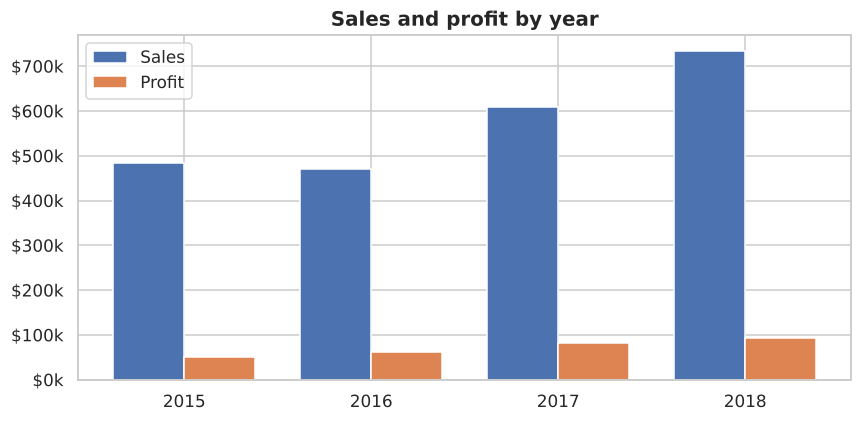

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(yearly)); w = 0.38
ax.bar(x - w/2, yearly["Sales"], w, label="Sales")
ax.bar(x + w/2, yearly["Profit"], w, label="Profit")
ax.set_xticks(x); ax.set_xticklabels(yearly.index)
ax.yaxis.set_major_formatter(money_k)
ax.set_title("Sales and profit by year"); ax.legend()
plt.tight_layout(); plt.savefig("images/01_yearly_sales_profit.png"); plt.show()

## 5. Customer purchase volume

In [11]:
cust = (df.groupby(["Customer ID", "Customer Name"])
          .agg(Orders=("Order ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
          .reset_index().sort_values("Sales", ascending=False))

top20_share = cust.head(int(len(cust) * 0.2))["Sales"].sum() / cust["Sales"].sum()
print(f"Customers                       : {len(cust)}")
print(f"Median orders per customer      : {cust['Orders'].median():.0f}")
print(f"Customers with 2+ orders        : {(cust['Orders'] > 1).mean():.1%}")
print(f"Top 20% of customers' sales share: {top20_share:.1%}")

Customers                       : 793
Median orders per customer      : 6
Customers with 2+ orders        : 98.5%
Top 20% of customers' sales share: 48.0%


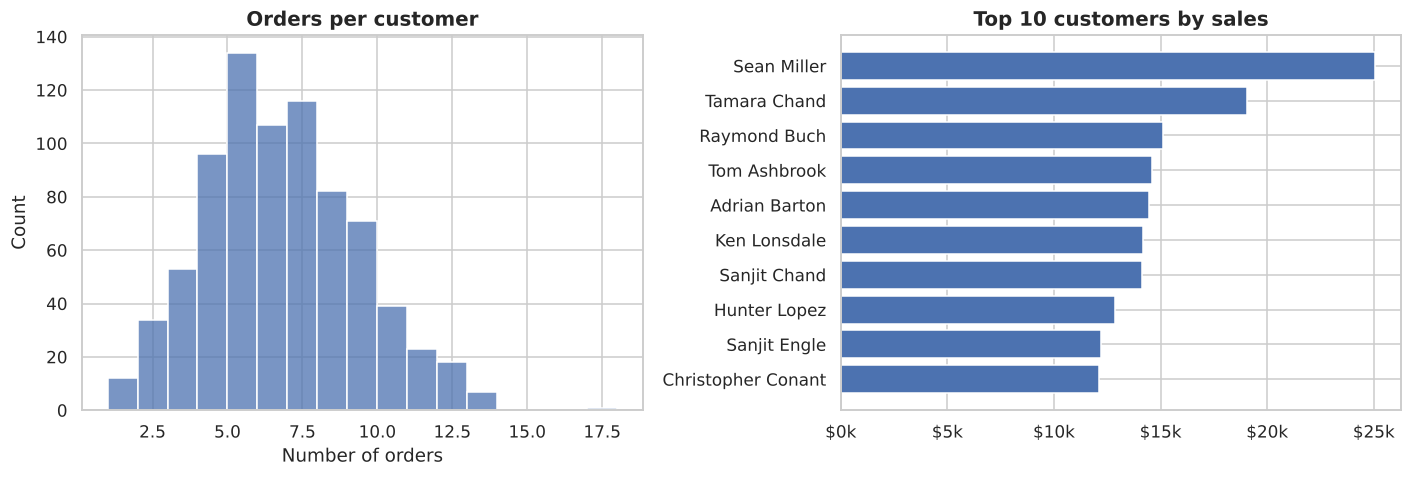

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(cust["Orders"], bins=range(1, 19), ax=axes[0])
axes[0].set_title("Orders per customer"); axes[0].set_xlabel("Number of orders")

top10 = cust.head(10).iloc[::-1]
axes[1].barh(top10["Customer Name"], top10["Sales"])
axes[1].xaxis.set_major_formatter(money_k)
axes[1].set_title("Top 10 customers by sales")
plt.tight_layout(); plt.savefig("images/02_customers.png"); plt.show()

## 6. Monthly seasonality

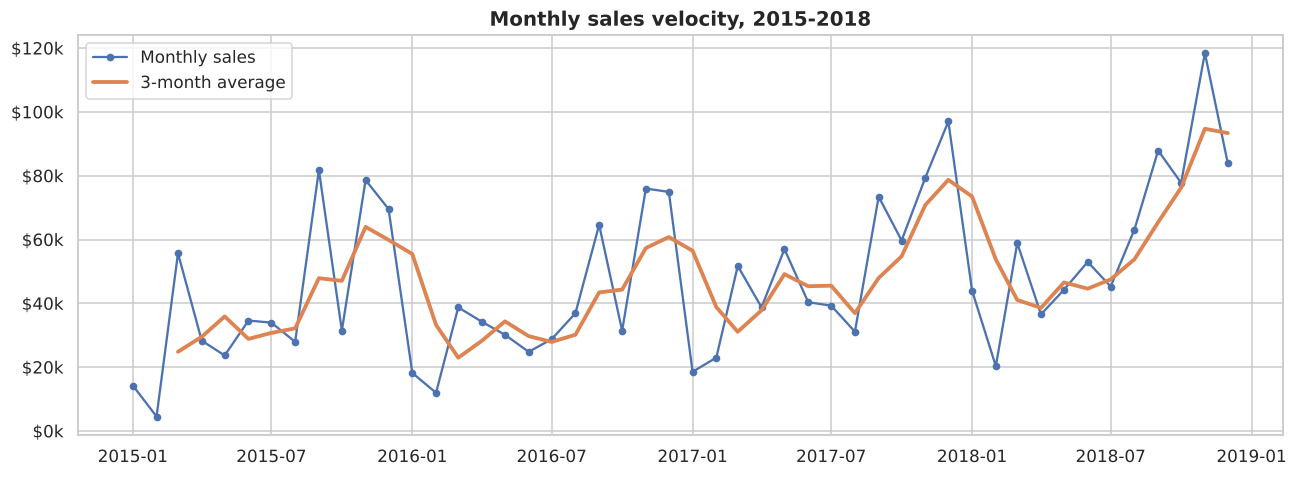

In [13]:
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.values, marker="o", ms=4, label="Monthly sales")
ax.plot(monthly.index, monthly.rolling(3).mean(), lw=2.5, label="3-month average")
ax.yaxis.set_major_formatter(money_k)
ax.set_title("Monthly sales velocity, 2015-2018"); ax.legend()
plt.tight_layout(); plt.savefig("images/03_monthly_sales.png"); plt.show()

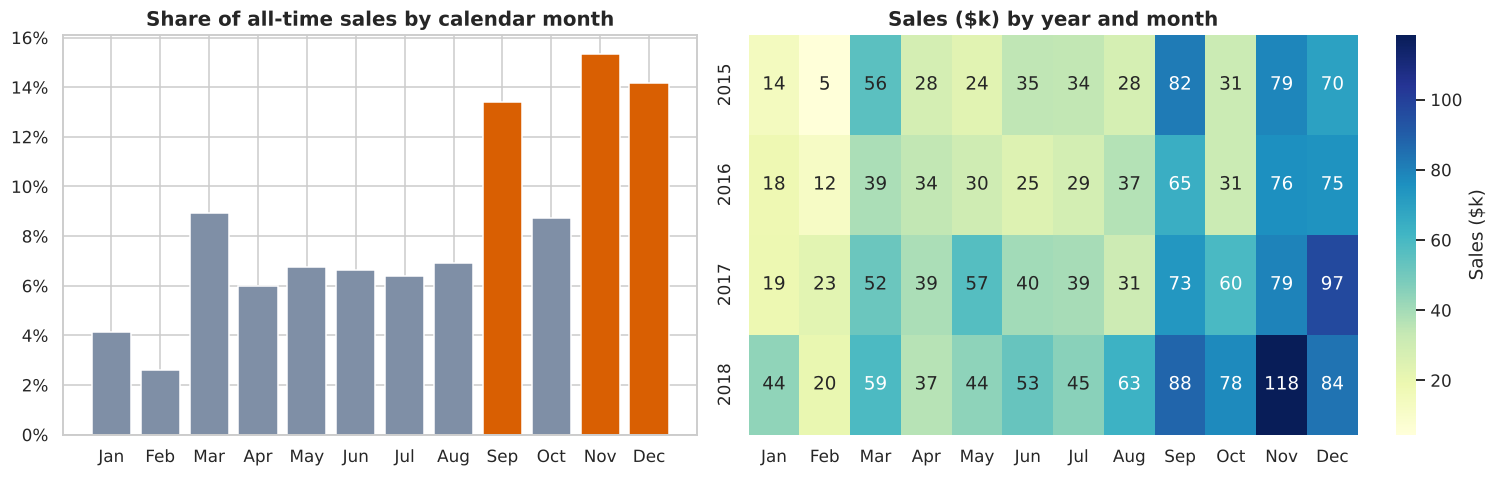

Sep + Nov + Dec share of sales: 42.9%
Jan + Feb share of sales      : 6.7%


In [14]:
moy = df.groupby("Month")["Sales"].sum()
share = moy / moy.sum()
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
colors = ["#d95f02" if s > 0.12 else "#7f8fa6" for s in share]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].bar(months, share.values, color=colors)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set_title("Share of all-time sales by calendar month")

pivot = df.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
pivot.columns = months
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Sales ($k)"}, ax=axes[1])
axes[1].set_title("Sales ($k) by year and month"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("images/04_seasonality.png"); plt.show()

print(f"Sep + Nov + Dec share of sales: {share[[9, 11, 12]].sum():.1%}")
print(f"Jan + Feb share of sales      : {share[[1, 2]].sum():.1%}")

## 7. Category, Region and Customer Segment performance

In [15]:
def summarize(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
    g["Margin"] = g["Profit"] / g["Sales"]
    g["Sales Share"] = g["Sales"] / g["Sales"].sum()
    g["Profit Share"] = g["Profit"] / g["Profit"].sum()
    return g.sort_values("Sales", ascending=False)

fmt = {"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Sales Share": "{:.1%}", "Profit Share": "{:.1%}"}
by_cat = summarize("Category")
by_cat.style.format(fmt)

,Sales,Profit,Orders,Margin,Sales Share,Profit Share
Category,,,,,,
Technology,"$836,154","$145,455",1544,17.4%,36.4%,50.8%
Furniture,"$742,000","$18,451",1764,2.5%,32.3%,6.4%
Office Supplies,"$719,047","$122,491",3742,17.0%,31.3%,42.8%


In [16]:
by_region = summarize("Region")
by_region.style.format(fmt)

,Sales,Profit,Orders,Margin,Sales Share,Profit Share
Region,,,,,,
West,"$725,458","$108,418",1611,14.9%,31.6%,37.9%
East,"$678,781","$91,523",1401,13.5%,29.5%,32.0%
Central,"$501,240","$39,706",1175,7.9%,21.8%,13.9%
South,"$391,722","$46,749",822,11.9%,17.1%,16.3%


In [17]:
by_segment = summarize("Segment")
by_segment.style.format(fmt)

,Sales,Profit,Orders,Margin,Sales Share,Profit Share
Segment,,,,,,
Consumer,"$1,161,401","$134,119",2586,11.5%,50.6%,46.8%
Corporate,"$706,146","$91,979",1514,13.0%,30.7%,32.1%
Home Office,"$429,653","$60,299",909,14.0%,18.7%,21.1%


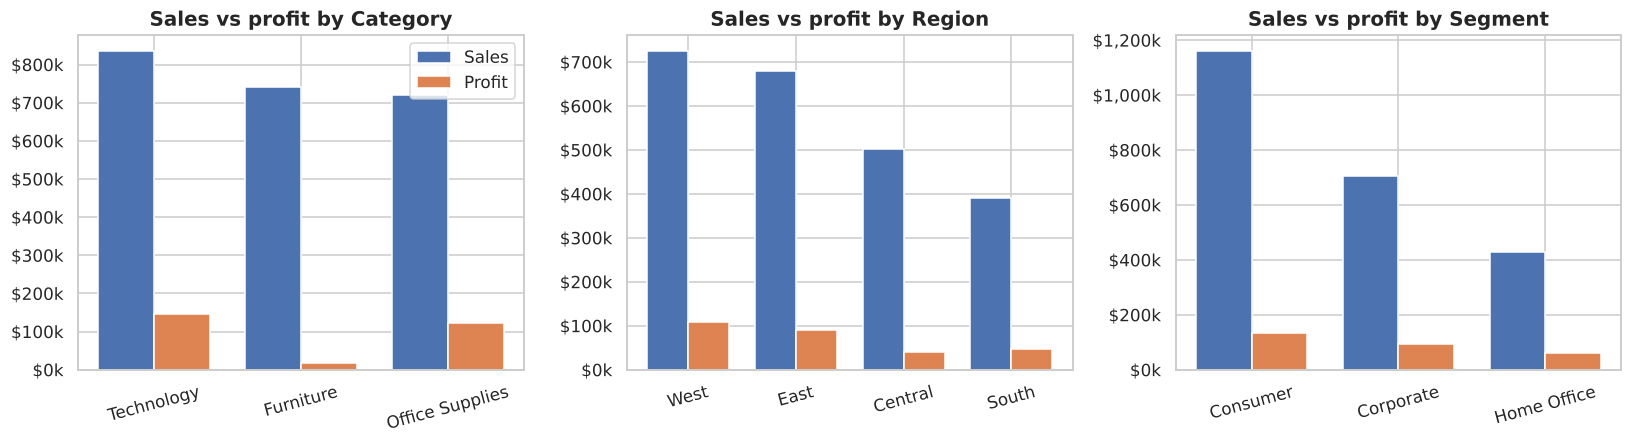

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (title, tbl) in zip(axes, [("Category", by_cat), ("Region", by_region), ("Segment", by_segment)]):
    idx = np.arange(len(tbl)); w = 0.38
    ax.bar(idx - w/2, tbl["Sales"], w, label="Sales")
    ax.bar(idx + w/2, tbl["Profit"], w, label="Profit")
    ax.set_xticks(idx); ax.set_xticklabels(tbl.index, rotation=15)
    ax.yaxis.set_major_formatter(money_k); ax.set_title(f"Sales vs profit by {title}")
axes[0].legend()
plt.tight_layout(); plt.savefig("images/05_category_region_segment.png"); plt.show()

### Sub-category profitability

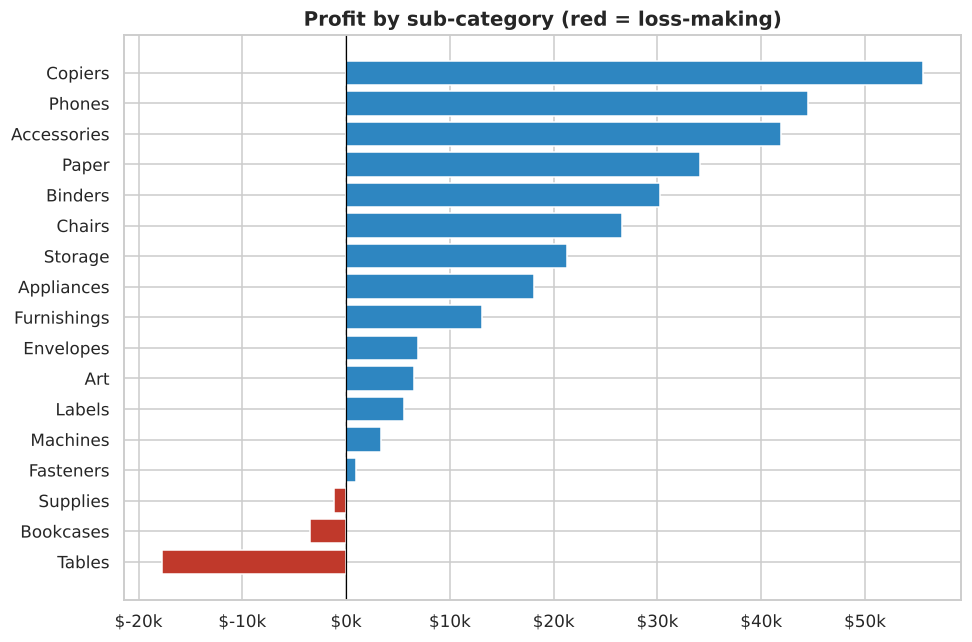

,Sales,Profit,Margin
Sub-Category,,,
Tables,"$206,966","$-17,725",-8.6%
Bookcases,"$114,880","$-3,473",-3.0%
Supplies,"$46,674","$-1,189",-2.5%


In [19]:
sub = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
sub["Margin"] = sub["Profit"] / sub["Sales"]
sub = sub.sort_values("Profit")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub["Profit"], color=["#c0392b" if p < 0 else "#2e86c1" for p in sub["Profit"]])
ax.xaxis.set_major_formatter(money_k)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Profit by sub-category (red = loss-making)")
plt.tight_layout(); plt.savefig("images/06_subcategory_profit.png"); plt.show()

sub[sub["Profit"] < 0].style.format({"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}"})

### Where do the problems sit? Region x Category margin, and the weakest states

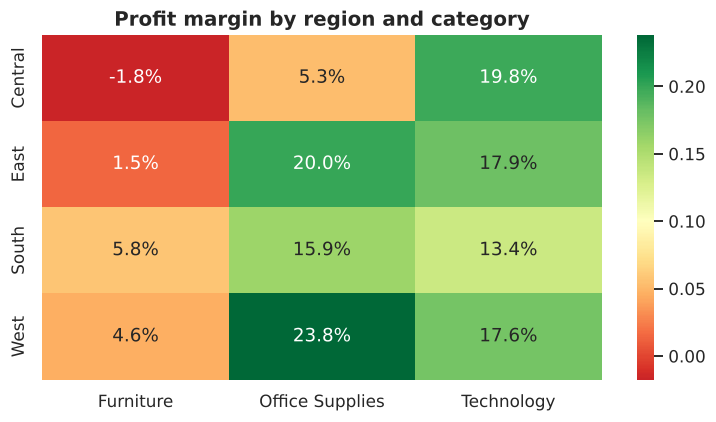

Five least profitable states:
State
Texas             $-25,729
Ohio              $-16,971
Pennsylvania      $-15,560
Illinois          $-12,608
North Carolina     $-7,491


In [20]:
rc = df.groupby(["Region", "Category"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
margin_rc = (rc["Profit"] / rc["Sales"]).unstack()

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(margin_rc, annot=True, fmt=".1%", cmap="RdYlGn", center=0.1, ax=ax)
ax.set_title("Profit margin by region and category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("images/07_region_category_margin.png"); plt.show()

state_profit = df.groupby("State")["Profit"].sum().sort_values()
print("Five least profitable states:")
print(state_profit.head(5).map("${:,.0f}".format).to_string())

In [21]:
# Is Central's weak margin linked to deeper discounting?
region_disc = df.groupby("Region").agg(Avg_Discount=("Discount", "mean"),
                                       Share_Lines_Over_20pct=("Discount", lambda s: (s > 0.2).mean()))
region_disc.style.format({"Avg_Discount": "{:.1%}", "Share_Lines_Over_20pct": "{:.1%}"})

,Avg_Discount,Share_Lines_Over_20pct
Region,,
Central,24.0%,27.7%
East,14.5%,16.2%
South,14.7%,10.6%
West,10.9%,3.7%


## 8. Discount sensitivity

Correlation between discount and profit: -0.22


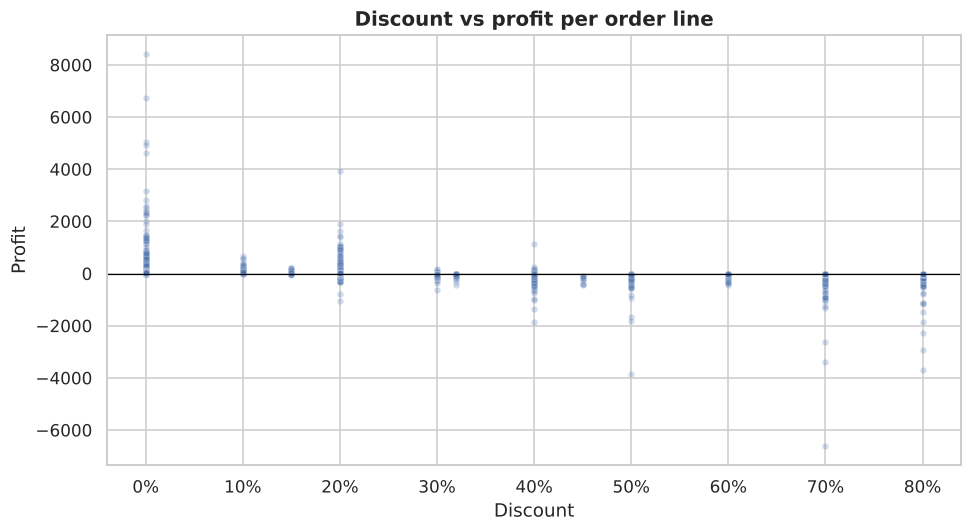

In [22]:
corr = df[["Discount", "Profit"]].corr().iloc[0, 1]
print(f"Correlation between discount and profit: {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.25, s=18, ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(pct0)
ax.set_title("Discount vs profit per order line")
plt.tight_layout(); plt.savefig("images/08_discount_scatter.png"); plt.show()

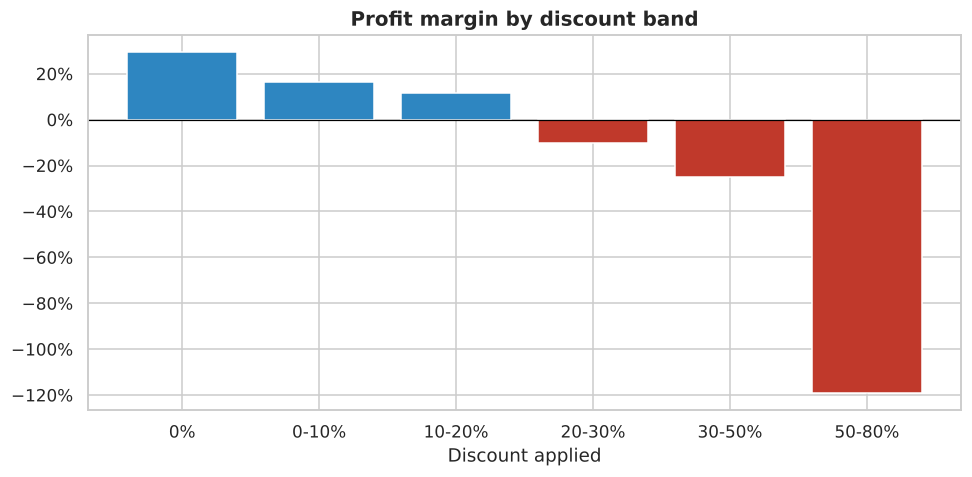

,Lines,Sales,Profit,Margin
Discount Band,,,,
0%,"4,798","$1,087,908","$320,988",29.5%
0-10%,94,"$54,369","$9,029",16.6%
10-20%,"3,709","$792,153","$91,756",11.6%
20-30%,227,"$103,227","$-10,369",-10.0%
30-50%,310,"$195,315","$-48,448",-24.8%
50-80%,856,"$64,229","$-76,559",-119.2%


In [23]:
bins = [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 0.8]
labels = ["0%", "0-10%", "10-20%", "20-30%", "30-50%", "50-80%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

band = df.groupby("Discount Band", observed=True).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
band["Margin"] = band["Profit"] / band["Sales"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(band.index.astype(str), band["Margin"], color=["#c0392b" if m < 0 else "#2e86c1" for m in band["Margin"]])
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Profit margin by discount band"); ax.set_xlabel("Discount applied")
plt.tight_layout(); plt.savefig("images/09_discount_band_margin.png"); plt.show()

band.style.format({"Lines": "{:,}", "Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}"})

In [24]:
heavy = df[df["Discount"] > 0.2]
loss = df[df["Is Loss"]]
print(f"Lines discounted over 20%       : {len(heavy):,} ({len(heavy)/len(df):.1%} of lines)")
print(f"Combined profit on those lines  : ${heavy['Profit'].sum():,.0f}")
print(f"Loss-making lines overall       : {len(loss):,} ({len(loss)/len(df):.1%}), total loss ${loss['Profit'].sum():,.0f}")
print(f"Share of loss-making lines with discount > 20%: {(loss['Discount'] > 0.2).mean():.1%}")

Lines discounted over 20%       : 1,393 (13.9% of lines)
Combined profit on those lines  : $-135,376
Loss-making lines overall       : 1,871 (18.7%), total loss $-156,131
Share of loss-making lines with discount > 20%: 72.0%


## 9. Returns (from the appended Returns table)

In [25]:
ret_orders = df.loc[df["Returned"], "Order ID"].nunique()
print(f"Returned orders: {ret_orders} of {df['Order ID'].nunique():,} ({ret_orders/df['Order ID'].nunique():.1%})")
print(f"Sales value on returned order lines: ${df.loc[df['Returned'], 'Sales'].sum():,.0f} "
      f"({df.loc[df['Returned'], 'Sales'].sum()/df['Sales'].sum():.1%} of all sales)")
df.groupby("Category")["Returned"].mean().map("{:.1%}".format)

Returned orders: 296 of 5,009 (5.9%)
Sales value on returned order lines: $180,504 (7.9% of all sales)


Category
Furniture          8.1%
Office Supplies    7.8%
Technology         8.4%
Name: Returned, dtype: str

## 10. Executive takeaways

**1. Growth is real, and profitability improved with it.**
Sales grew from **$484k (2015) to $733k (2018)** after a small dip in 2016 (-2.8%), then **+29.5% in 2017 and +20.4% in 2018**. Profit margin rose from **10.2% to 12.7%**. Overall: **$2.30M sales, $286k profit, 12.5% margin**.

**2. Demand is highly seasonal and concentrated in Q4.**
**September, November and December generate about 43% of all sales** (13.4%, 15.3% and 14.2%), while **January and February together deliver only 6.7%**. Inventory, staffing and marketing spend should be planned around this curve, with a secondary bump in March (8.9%).

**3. Furniture sells like a growth category but earns like a charity.**
Furniture brings in **$742k (32% of sales) but only $18k of profit (6% of profit, 2.5% margin)**. Technology (17.4% margin) and Office Supplies (17.0%) carry the business. Within Furniture, **Tables (-8.6% margin, -$17.7k) and Bookcases (-3.0%) lose money**, and Supplies also loses money at -2.5%.

**4. Discounts above 20% destroy profit.**
Undiscounted lines earn a **29.5% margin**; lines in the 10-20% band earn 11.6%; beyond 20% every band is loss-making: **20-30% = -10.0%, 30-50% = -24.8%, 50-80% = -119%**. The 1,393 lines discounted over 20% (14% of all lines) lose about **$135k combined**, and **72% of all loss-making lines carry a discount above 20%**. Discount and profit are negatively correlated (r = -0.22).

**5. The Central region is the weak spot.**
Central earns a **7.9% margin versus 14.9% in the West**, and Central Furniture is loss-making (-$2.9k on $164k of sales). The least profitable states are **Texas (-$25.7k), Ohio (-$17.0k), Pennsylvania (-$15.6k) and Illinois (-$12.6k)**. A likely driver is discounting: Central averages a **24.0% discount (27.7% of its lines are discounted above 20%)**, versus 10.9% in the West (3.7% of lines above 20%). This ties directly back to takeaway 4.

**6. The customer base is loyal and evenly spread.**
**98.5% of the 793 customers ordered more than once** (median: 6 orders), and the **top 20% of customers account for 48% of sales**. That is far flatter than the typical 80/20 pattern, so growth depends more on keeping many repeat buyers happy than on a few big accounts. By segment, Consumer is the largest (51% of sales), but **Home Office has the best margin (14.0% vs 11.5%)**.

**Bonus, data quality:** about **6% of orders (296 of 5,009)** appear in the Returns table, representing roughly 8% of sales value, which is worth monitoring as a leakage source.

### Recommendations
1. **Cap discounts at 20%** and require approval above it. Starting with Tables and Bookcases, this is the single biggest lever on profit in this dataset.
2. **Reprice or rethink Tables and Bookcases**, and review supplier cost or minimum margin for loss-making sub-categories.
3. **Plan the year around Q4**: build inventory and campaigns before September, and use January-February for clearance or retention offers rather than acquisition.
4. **Investigate the Central region** (discount depth, product mix, shipping cost) and the four loss-making states.
5. **Nurture repeat customers**: loyalty or bundle offers suit a base that is already highly repeat-driven.

### Limitations
- This is order-line data from one retailer over four years, so findings describe associations and not proven causes (for example, discounting may be a response to slow-moving stock).
- Profit is as recorded in the source, and shipping and overhead costs are not available.
- The Burlington, VT postal code was filled from outside knowledge (section 2).